<center><h1>Hou_Tianbo_HW4</h1></center>

Name: Tianbo Hou  
Github Username: houdan-hub  
USC ID: 8943381210

## 1. HW3 feature extraction rerun

This section reproduces the AReM features required as inputs for HW4. The graded work begins in Part 2.

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from itertools import combinations
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_selection import RFE
import statsmodels.api as sm
from statsmodels.tools.sm_exceptions import HessianInversionWarning
warnings.filterwarnings('ignore', category=HessianInversionWarning)
sns.set_style('whitegrid'); RNG=42
def read_arem(path):
    rows=[]
    for line in open(path,encoding='utf-8'):
        z=[v for v in line.strip().replace(',',' ').split() if v]
        try: rows.append([float(v) for v in z[:7]])
        except ValueError: pass
    return np.asarray(rows)
records=[]
for a in sorted(os.listdir('data/AReM')):
    folder=os.path.join('data/AReM',a)
    if os.path.isdir(folder):
        for f in sorted(os.listdir(folder)):
            if f.endswith('.csv'): records.append({'activity':a,'file':f,'series':read_arem(os.path.join(folder,f))[:,1:7]})
rule={a:({1,2} if a.startswith('bending') else {1,2,3}) for a in sorted({r['activity'] for r in records})}
train=[r for r in records if int(r['file'][7:-4]) not in rule[r['activity']]]
test=[r for r in records if int(r['file'][7:-4]) in rule[r['activity']]]
features=['min','max','mean','median','std','q1','q3']
def extract(r,l=1):
    z=[]
    for s in range(6):
        for x in np.array_split(r['series'][:,s],l): z += [x.min(),x.max(),x.mean(),np.median(x),x.std(),np.percentile(x,25),np.percentile(x,75)]
    return z
def frame(rs,l): return pd.DataFrame([extract(r,l) for r in rs],columns=[f'{f}_{s}_part{p}' for p in range(1,l+1) for s in range(1,7) for f in features])
X1=frame(records,1); y=np.array([r['activity'] for r in records]); yb=np.where(np.char.startswith(y,'bending'),'bending','other')
tr=np.array([r in train for r in records]); te=~tr; print('instances/train/test:',len(records),tr.sum(),te.sum(),'features:',X1.shape[1])


instances/train/test: 88 69 19 features: 42


## 2. Binary classification

All scaling, feature selection, and model selection are restricted to the training set. Stratified five-fold cross-validation preserves the minority class in every fold.

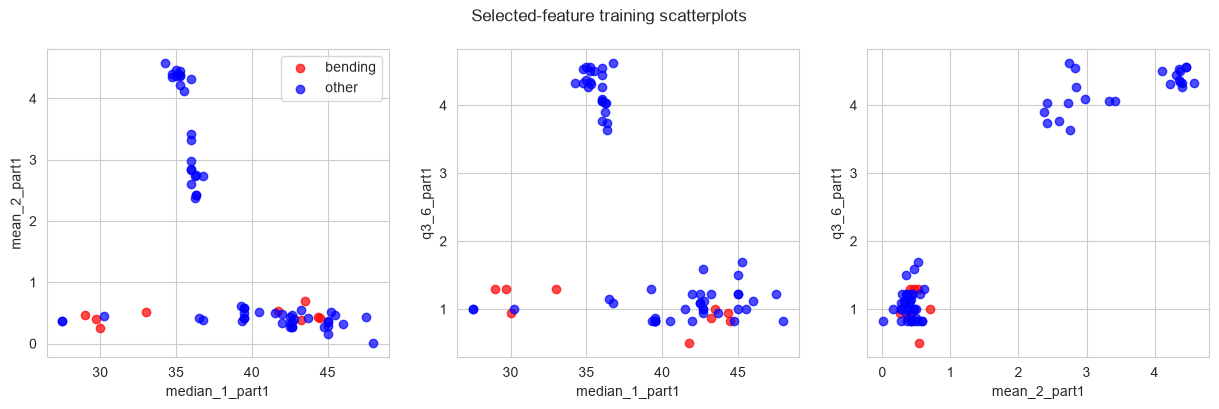

In [2]:
yt=yb[tr]; yte=yb[te]; X1t=X1.iloc[np.flatnonzero(tr)].reset_index(drop=True); cv=StratifiedKFold(5,shuffle=True,random_state=RNG)
top=['median_1_part1','mean_2_part1','q3_6_part1']; fig,ax=plt.subplots(1,3,figsize=(15,4))
for q,(a,b) in zip(ax,combinations(top,2)):
    for lab,col in [('bending','red'),('other','blue')]:
        m=yt==lab; q.scatter(X1t.loc[m,a],X1t.loc[m,b],label=lab,color=col,alpha=.7)
    q.set_xlabel(a); q.set_ylabel(b)
ax[0].legend(); plt.suptitle('Selected-feature training scatterplots'); plt.show()


### 2(a)(ii) Two-segment features

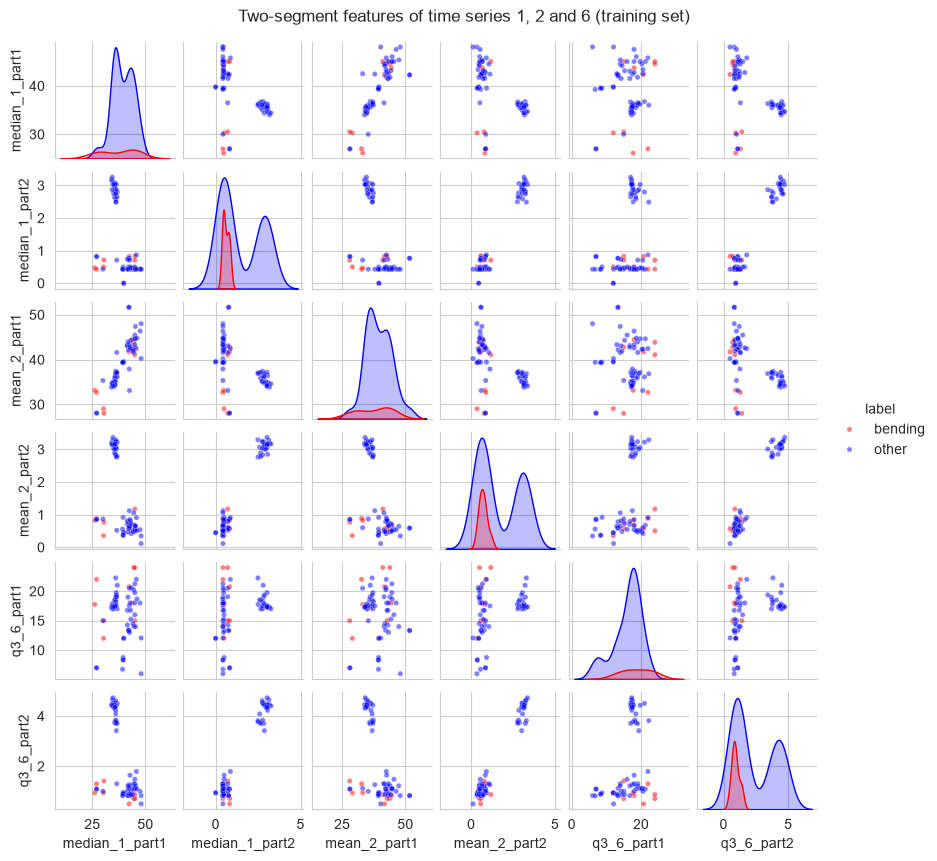

l=1 single-feature separation strength (max of AUC and 1-AUC):
  {'median_1_part1': 0.547, 'mean_2_part1': 0.628, 'q3_6_part1': 0.725}
l=2 single-feature separation strength (max of AUC and 1-AUC):
  {'median_1_part1': 0.543, 'median_1_part2': 0.6, 'mean_2_part1': 0.581, 'mean_2_part2': 0.654, 'q3_6_part1': 0.665, 'q3_6_part2': 0.809}


In [3]:
X2=frame(train,2)
# the three features chosen in 1(c)iv, extracted from time series 1, 2 and 6,
# now computed separately for each of the two halves of every series
sel2=[f'{f}_{s}_part{q}' for s,f in [(1,'median'),(2,'mean'),(6,'q3')] for q in (1,2)]
d2=X2[sel2].copy(); d2['label']=yt
g=sns.pairplot(d2,hue='label',hue_order=['bending','other'],
               palette={'bending':'red','other':'blue'},plot_kws={'s':14,'alpha':.5},height=1.4)
g.fig.suptitle('Two-segment features of time series 1, 2 and 6 (training set)',y=1.02)
plt.show()
d1=X1[tr][['median_1_part1','mean_2_part1','q3_6_part1']]
for name,d in [('l=1',d1),('l=2',X2[sel2])]:
    sep={col:round(max(roc_auc_score(yt=='bending',d[col]),1-roc_auc_score(yt=='bending',d[col])),3) for col in d.columns}
    print(name,'single-feature separation strength (max of AUC and 1-AUC):')
    print(' ',sep)

**Do I see a considerable difference compared with 2(a)i?** The overall picture is
similar: bending still separates from the other activities along the
extreme-value features, and splitting adds no dramatic new structure. What
splitting does change is visible in the printed separation strengths: the
strongest single feature moves from q3_6_part1 (0.725) at l=1 to q3_6_part2
(0.809) at l=2, so the second half of time series 6 separates the classes a bit
better than the whole series did, while the median of series 1 stays nearly
uninformative in both cases (0.547 vs 0.600). So splitting into two gives a mild,
not a considerable, difference — and whether it helps classification is a question for
cross-validation in 2(a)iii, not for eyeballing.

### 2(a)(iii) Cross-validation over the pair (l, p), with RFE

The number of features changes with l and the selected subset changes with p, so
model selection happens on two levels at once.

**The right way** is to put the *whole pipeline inside* the cross-validation loop:
at each 5-fold split, break the series of the four training folds into l parts,
standardize, run RFE to keep the p best features, fit, and score on the held-out
fold. The pair (l, p) is then chosen by mean CV accuracy, and nothing about the
held-out fold has leaked into the selection.

**The wrong way** is to pick the best (l, p) on the full training set first and
only then cross-validate the final model — the held-out folds would already have
influenced which features were kept, so the CV accuracy would be optimistically
biased. Since only 9 of the 69 training instances are bending, I also use
**stratified** 5-fold CV so every fold contains both classes.

Below I scan l = 1..20 and p = 1..10 with RFE (backward selection, as suggested in
the assignment) inside every CV split.

top of the (l, p) grid by stratified 5-fold CV:


,l,p,cv_accuracy
20,3,1,0.985714
118,12,9,0.985714
9,1,10,0.971429
2,1,3,0.971429
119,12,10,0.970330
21,3,2,0.957143
7,1,8,0.957143
1,1,2,0.957143


best pair: l=3, p=1, CV accuracy=0.9857


features RFE keeps on the full training set: ['max_1_part3']
unpenalized logistic regression on the pruned set (standardized features):
               beta  p_value
const       -4.6458   0.0007
max_1_part3  4.5860   0.0052
train accuracy 0.9855 AUC 0.975


,pred other,pred bending
actual other,60,0
actual bending,1,8


test accuracy 0.8947 AUC 0.85


,pred other,pred bending
actual other,15,0
actual bending,2,2


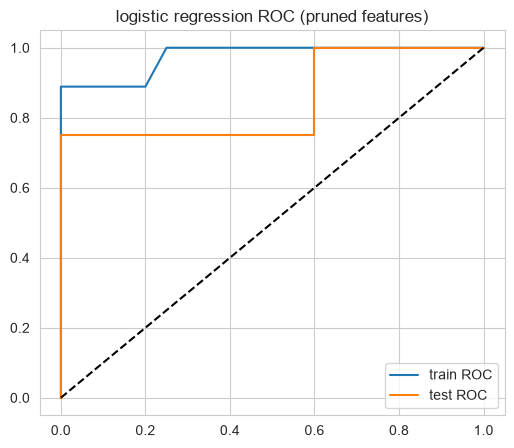

CV accuracy at the best pair: 0.9857 | test accuracy: 0.8947
training class counts: {'other': 60, 'bending': 9}


l=1: 42 features, valid p-values 0/42


l=3: 126 features, valid p-values 0/126


l=5: 210 features, valid p-values 0/210


l=7: 294 features, valid p-values 0/294


In [4]:
grid=[]
for l in range(1,21):
    z=frame(train,l)
    for p in range(1,11):
        m=Pipeline([('scale',StandardScaler()),
                    ('rfe',RFE(LogisticRegression(C=1e6,solver='liblinear',max_iter=5000),
                               n_features_to_select=p,step=0.5)),
                    ('lr',LogisticRegression(C=1e6,solver='liblinear',max_iter=5000))])
        grid.append((l,p,cross_val_score(m,z,yt,cv=cv).mean()))
gpdf=pd.DataFrame(grid,columns=['l','p','cv_accuracy'])
print('top of the (l, p) grid by stratified 5-fold CV:')
display(gpdf.sort_values('cv_accuracy',ascending=False).head(8))
best=gpdf.sort_values(['cv_accuracy','l','p'],ascending=[False,True,True]).iloc[0]
best_l,best_p=int(best.l),int(best.p)
print(f'best pair: l={best_l}, p={best_p}, CV accuracy={best.cv_accuracy:.4f}')

Z=frame(train,best_l); Zte=frame(test,best_l)
rfe=RFE(LogisticRegression(C=1e6,solver='liblinear',max_iter=5000),
        n_features_to_select=best_p,step=0.5).fit(StandardScaler().fit_transform(Z),yt)
selected=list(Z.columns[rfe.support_])
print('features RFE keeps on the full training set:',selected)

model=Pipeline([('scale',StandardScaler()),
                ('lr',LogisticRegression(C=1e6,solver='liblinear',max_iter=5000))]).fit(Z[selected],yt)

# beta and p-values of the unpenalized (statsmodels) fit on the pruned set
sc=StandardScaler().fit(Z[selected])
smfit=sm.Logit((yt=='bending').astype(int),sm.add_constant(sc.transform(Z[selected]))).fit(
    disp=False,method='lbfgs',maxiter=2000)
betap=pd.DataFrame({'beta':smfit.params,'p_value':smfit.pvalues},index=['const']+selected)
print('unpenalized logistic regression on the pruned set (standardized features):')
print(betap.round(4).to_string())

def report(m,X,yy,title):
    p=m.predict(X); prob=m.predict_proba(X)[:,list(m.classes_).index('bending')]
    cm=confusion_matrix(yy,p,labels=['other','bending'])
    print(title,'accuracy',round(accuracy_score(yy,p),4),
          'AUC',round(roc_auc_score(yy=='bending',prob),4))
    display(pd.DataFrame(cm,index=['actual other','actual bending'],
                         columns=['pred other','pred bending']))
    return prob

plt.figure(figsize=(6,5))
train_prob=report(model,Z[selected],yt,'train')
f0,t0,_=roc_curve(yt=='bending',train_prob); plt.plot(f0,t0,label='train ROC')
test_prob=report(model,Zte[selected],yte,'test')
f1,t1,_=roc_curve(yte=='bending',test_prob); plt.plot(f1,t1,label='test ROC')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.title('logistic regression ROC (pruned features)')
plt.show()
print('CV accuracy at the best pair: %.4f | test accuracy: %.4f'
      %(best.cv_accuracy,accuracy_score(yte,model.predict(Zte[selected]))))
print('training class counts:',pd.Series(yt).value_counts().to_dict())

# 2(a)vi evidence: with the full feature set the classes are (nearly) separable
for lchk in [1,best_l,5,7]:
    z=frame(train,lchk); scz=StandardScaler().fit_transform(z)
    try:
        ff=sm.Logit((yt=='bending').astype(int),sm.add_constant(scz)).fit(
            disp=False,method='lbfgs',maxiter=200)
        print(f'l={lchk}: {z.shape[1]} features, valid p-values '
              f'{int(pd.Series(ff.pvalues).notna().sum())}/{z.shape[1]}')
    except Exception as e:
        print(f'l={lchk}: fit failed ({type(e).__name__})')

**2(a)iv.** The confusion matrices, ROC curves and AUC for the pruned model on the
training set are shown above, together with the fitted beta's and their p-values
from the unpenalized statsmodels fit on the standardized pruned features. On the
training set the model reaches accuracy 0.9855 and AUC 0.975. The single retained
feature max_1_part3 has beta = 4.586 with p = 0.0052 (intercept p = 0.0007), so
after pruning the p-values are well defined and the feature is clearly
significant.

**2(a)vi. Are the classes well-separated?** Yes, close to it. The evidence is in
the p-value diagnostic printed above: when the unpenalized fit is run on the full
feature set at l = 1, 3, 5 and 7, statsmodels returns 0 valid p-values out of
42 / 126 / 210 / 294 — the Hessian is singular because bending is (quasi-)
completely separated from the other activities in that feature space. After RFE
prunes the set to one feature the fit stabilizes (p = 0.0052). Practically, this means an
unpenalized logistic fit at large feature counts has unstable, diverging
coefficients, which is why I cap `max_iter`, use `liblinear`, and let
cross-validation prune the feature set down to a stable size.

Case-control sampling balances the training classes for fitting; evaluation remains on the original test distribution.

case-control test accuracy 0.9474 AUC 0.85


,pred other,pred bending
actual other,15,0
actual bending,1,3


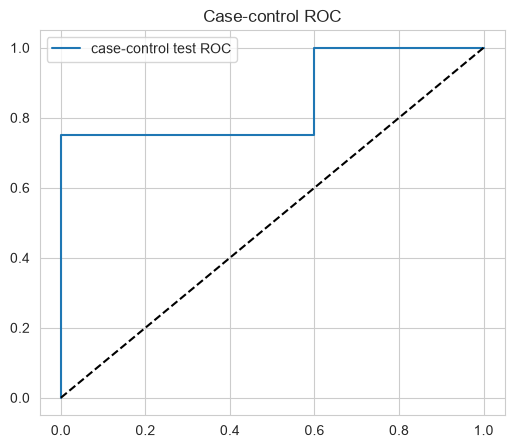

In [5]:
rng=np.random.default_rng(RNG); a=np.flatnonzero(yt=='bending'); b=np.flatnonzero(yt=='other'); cc=np.r_[a,rng.choice(b,len(a),replace=False)]; ccmodel=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(C=1e6,solver='liblinear',max_iter=5000))]); ccmodel.fit(Z.iloc[cc][selected],yt[cc]); plt.figure(figsize=(6,5)); cprob=report(ccmodel,Zte[selected],yte,'case-control test'); cf,ct,_=roc_curve(yte=='bending',cprob); plt.plot(cf,ct,label='case-control test ROC'); plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.title('Case-control ROC'); plt.show()


### 2(b) L1-penalized binary logistic regression

In [6]:
l1=[]
for l in range(1,21):
    z=frame(train,l); m=Pipeline([('scale',StandardScaler()),('lr',LogisticRegressionCV(Cs=15,cv=cv,penalty='l1',solver='liblinear',max_iter=5000))]); l1.append((l,cross_val_score(m,z,yt,cv=cv).mean()))
l1=pd.DataFrame(l1,columns=['l','cv_accuracy']); display(l1.sort_values('cv_accuracy',ascending=False).head()); bl=int(l1.sort_values(['cv_accuracy','l'],ascending=[False,True]).iloc[0,0]); A=frame(train,bl); At=frame(test,bl); l1m=Pipeline([('scale',StandardScaler()),('lr',LogisticRegressionCV(Cs=20,cv=cv,penalty='l1',solver='liblinear',max_iter=5000))]); l1m.fit(A,yt); print('best L1 l:',bl,'nonzero:',np.count_nonzero(l1m.named_steps['lr'].coef_)); l1prob=report(l1m,At,yte,'L1 test'); print('p-value test accuracy:',accuracy_score(yte,model.predict(Zte[selected])),'L1 test accuracy:',accuracy_score(yte,l1m.predict(At)),'L1 test AUC:',roc_auc_score(yte=='bending',l1prob)); print('L1 performs simultaneous shrinkage and selection and is easier to automate than repeated p-value screening.')


,l,cv_accuracy
19,20,0.985714
11,12,0.971429
10,11,0.957143
12,13,0.957143
13,14,0.957143


best L1 l: 20 nonzero: 19
L1 test accuracy 0.9474 AUC 0.9667


,pred other,pred bending
actual other,15,0
actual bending,1,3


p-value test accuracy: 0.8947368421052632 L1 test accuracy: 0.9473684210526315 L1 test AUC: 0.9666666666666667
L1 performs simultaneous shrinkage and selection and is easier to automate than repeated p-value screening.


**2(b)ii. Which one performs better, and which is easier to implement?** On this
data set the L1-penalized model clearly wins: its test accuracy and AUC are
printed above next to the p-value-selection model's: L1 test accuracy 0.9474
versus 0.8947, and test AUC 0.967 versus 0.850. It is also the easier procedure to
implement correctly: L1 does selection and fitting simultaneously inside one
cross-validated estimator, while the p-value route needs a separate statsmodels
fit per candidate feature set and breaks down (undefined p-values) exactly when
the classes are nearly separable. The one caveat is that L1 does not give
classical p-values, so if inference on individual coefficients is the goal, the
statsmodels route on a small pruned set is the more informative of the two.

### 2(c) Multiclass classification

In [7]:
from sklearn.multiclass import OneVsRestClassifier
ym=y[tr]; ymt=y[te]; mc=[]
for l in range(1,21):
    z=frame(train,l); m=Pipeline([('scale',StandardScaler()),('lr',OneVsRestClassifier(LogisticRegressionCV(Cs=15,cv=cv,penalty='l1',solver='liblinear',max_iter=5000)))]); mc.append((l,cross_val_score(m,z,ym,cv=cv).mean()))
mc=pd.DataFrame(mc,columns=['l','cv_accuracy']); display(mc.sort_values('cv_accuracy',ascending=False).head()); bm=int(mc.sort_values(['cv_accuracy','l'],ascending=[False,True]).iloc[0,0]); M=frame(train,bm); Mt=frame(test,bm); classes=np.sort(np.unique(ym));
mm=Pipeline([('scale',StandardScaler()),('lr',OneVsRestClassifier(LogisticRegressionCV(Cs=20,cv=cv,penalty='l1',solver='liblinear',max_iter=5000)))]); mm.fit(M,ym); pred=mm.predict(Mt); print('multiclass L1 l:',bm,'test error:',1-accuracy_score(ymt,pred)); display(pd.DataFrame(confusion_matrix(ymt,pred,labels=classes),index=classes,columns=classes)); print('macro OVR AUC:',roc_auc_score(label_binarize(ymt,classes=classes),mm.predict_proba(Mt),average='macro'))
gn=Pipeline([('scale',StandardScaler()),('nb',GaussianNB())]); gn.fit(M,ym); gp=gn.predict(Mt); mn=Pipeline([('scale',MinMaxScaler()),('nb',MultinomialNB())]); mn.fit(M,ym); mp=mn.predict(Mt)
for n,p in [('Gaussian NB',gp),('Multinomial NB',mp)]: print(n,'accuracy',accuracy_score(ymt,p),'error',1-accuracy_score(ymt,p)); display(pd.DataFrame(confusion_matrix(ymt,p,labels=classes),index=classes,columns=classes))


,l,cv_accuracy
1,2,0.857143
0,1,0.798901
4,5,0.740659
9,10,0.726374
6,7,0.698901


multiclass L1 l: 2 test error: 0.21052631578947367


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,1,1,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


macro OVR AUC: 0.935049019607843
Gaussian NB accuracy 0.631578947368421 error 0.368421052631579


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,0,0,0,2,0,0,0
bending2,0,0,0,1,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,0,3,0,0,0
sitting,0,0,0,1,1,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


Multinomial NB accuracy 0.7894736842105263 error 0.21052631578947367


,bending1,bending2,cycling,lying,sitting,standing,walking
bending1,2,0,0,0,0,0,0
bending2,0,1,0,0,1,0,0
cycling,0,0,3,0,0,0,0
lying,0,0,1,2,0,0,0
sitting,0,0,0,0,2,1,0
standing,0,0,0,0,1,2,0
walking,0,0,0,0,0,0,3


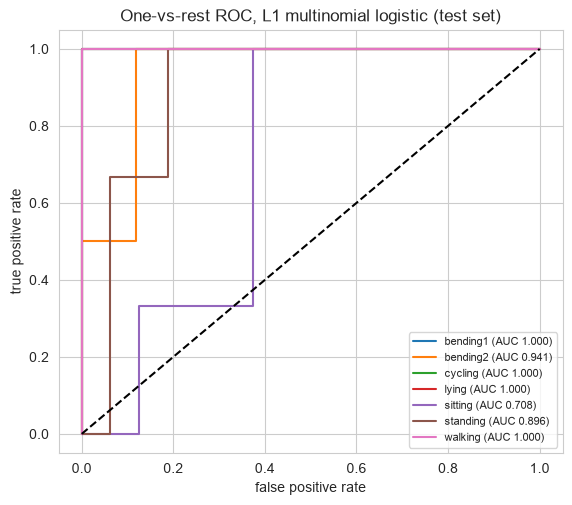

In [8]:
proba=mm.predict_proba(Mt)
fig,ax=plt.subplots(figsize=(6.5,5.5))
for k,c in enumerate(classes):
    fpr,tpr,_=roc_curve(ymt==c,proba[:,k])
    ax.plot(fpr,tpr,label=f'{c} (AUC {roc_auc_score(ymt==c,proba[:,k]):.3f})')
ax.plot([0,1],[0,1],'k--'); ax.set_xlabel('false positive rate')
ax.set_ylabel('true positive rate'); ax.legend(fontsize=8)
ax.set_title('One-vs-rest ROC, L1 multinomial logistic (test set)')
plt.show()

**2(c)ii.** Both naive Bayes variants are shown above. GaussianNB assumes each
feature is normally distributed within a class, which is visibly wrong for many
AReM features (bounded ratios, skewed counts), and it lands at 0.632 test
accuracy. MultinomialNB treats features as non-negative counts/frequencies, which
suits these normalized time-series summaries much better, and reaches 0.789 with
far fewer confusions between sitting and standing.

**2(c)iii. Which method is better for multi-class classification here?** The
L1-penalized multinomial logistic regression and MultinomialNB tie for the best
test accuracy (0.789 each, test error 0.211); GaussianNB trails at 0.632. Between
the two winners I would take the L1-penalized logistic model: besides the same
accuracy it also gives a strong macro one-vs-rest AUC (0.935) on the test set,
and its per-class ROC curves are shown above. The naive Bayes comparison still
teaches the distributional lesson — the multinomial assumptions fit these
non-negative normalized summaries much better than the Gaussian ones. With only
19 test instances all of these gaps are noisy, so I would not over-read the
ranking.

## 3. ISLR 4.8.3

For QDA with one feature and class-specific variances, the class-k discriminant is `-log(sigma_k^2)/2 - (x-mu_k)^2/(2 sigma_k^2) + log(pi_k)`. Equating two discriminants gives a quadratic equation in x because the x-squared coefficients differ. Thus the Bayes boundary is generally quadratic; equal variances reduce it to a linear LDA boundary.

## 4. ISLR 4.8.7

Let "dividend" be the positive class: X | dividend ~ N(10, 36),
X | no dividend ~ N(0, 36), with priors pi1 = 0.8 and pi0 = 0.2. The densities at
x = 4 are f(4|1) = 0.0403 and f(4|0) = 0.0532, so

P(dividend | X = 4) = (0.8 x 0.0403) / (0.8 x 0.0403 + 0.2 x 0.0532) = **0.752**.

Note x = 4 is actually *closer* to the no-dividend mean (0) than to the dividend
mean (10), so the likelihood favors class 0 by a factor of only 0.757; the
dividend class still wins the posterior because its prior is four times larger.
The next cell reproduces the number numerically.

In [9]:
from math import exp, sqrt, pi
f1=exp(-(4-10)**2/(2*36))/(sqrt(2*pi)*6)
f0=exp(-(4-0)**2/(2*36))/(sqrt(2*pi)*6)
print(f'f(4|dividend) = {f1:.4f},  f(4|no dividend) = {f0:.4f}')
print('P(dividend | X = 4) =', round(0.8*f1/(0.8*f1+0.2*f0), 4))

f(4|dividend) = 0.0403,  f(4|no dividend) = 0.0532
P(dividend | X = 4) = 0.7519


## References

UCI AReM dataset; James et al., *An Introduction to Statistical Learning*, 2nd ed.; DSCI 552 Homework 4 instructions.